In [2]:
from functools import reduce
import importlib

import polars as pl

import Amihud_factor as amihud_factor_module
import DailyPriceVolume_factor as daily_price_volume_module
import Liquid_factor as liquid_factor_module

importlib.reload(amihud_factor_module)
importlib.reload(daily_price_volume_module)
importlib.reload(liquid_factor_module)

Amihud_factor = amihud_factor_module.Amihud_factor
DailyPriceVolume_factor = daily_price_volume_module.DailyPriceVolume_factor
Liquid_factor = liquid_factor_module.Liquid_factor

START_DATE = "2023-01-01"
END_DATE = "2026-01-01"
BLAZE_STORE_PATH = r"G:\BlazeStore"

daily_price_volume = DailyPriceVolume_factor(BLAZE_STORE_PATH)
amihud = Amihud_factor(BLAZE_STORE_PATH)
liquid = Liquid_factor(BLAZE_STORE_PATH)


In [3]:
def join_factor_lazyframes(factor_lfs: list[pl.LazyFrame]) -> pl.LazyFrame:
    """按 date、asset 连接同一类因子的 LazyFrame，不触发 collect。"""
    return reduce(
        lambda left, right: left.join(
            right,
            on=["date", "asset"],
            how="outer",
            coalesce=True,
            validate="1:1",
        ),
        factor_lfs,
    )


def collect_factor_group(
    factor_class,
    factor_functions: list,
    start_date: str = START_DATE,
    end_date: str = END_DATE,
) -> pl.LazyFrame:
    """用一个类的 collect_lazyframe 收集并连接该类的全部因子。"""
    factor_lfs = [
        factor_class.collect_lazyframe(start_date, end_date, factor_func)
        for factor_func in factor_functions
    ]
    return join_factor_lazyframes(factor_lfs)


In [5]:
daily_price_volume_functions = [
    # lambda d: daily_price_volume.calc_ret_nd(d, n=1),
    # lambda d: daily_price_volume.calc_ret_nd(d, n=5),
    # lambda d: daily_price_volume.calc_ret_nd(d, n=10),
    # lambda d: daily_price_volume.calc_ret_nd(d, n=20),
    # lambda d: daily_price_volume.calc_ret_nd(d, n=60),
    lambda d: daily_price_volume.calc_exret_nd(d, n=1, index_asset="000001"),
    lambda d: daily_price_volume.calc_exret_nd(d, n=5, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=10, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=20, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=60, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=80, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=100, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=120, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=150, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=180, index_asset="000001"),
    # lambda d: daily_price_volume.calc_exret_nd(d, n=260, index_asset="000001"),
    # lambda d: daily_price_volume.calc_vol_nd(d, n=5),
    # lambda d: daily_price_volume.calc_vol_nd(d, n=20),
    # lambda d: daily_price_volume.calc_vol_nd(d, n=60),
    # lambda d: daily_price_volume.calc_volume_ratio_nd(d, n=5),
    # lambda d: daily_price_volume.calc_volume_ratio_nd(d, n=20),
    # lambda d: daily_price_volume.calc_volume_ratio_nd(d, n=60),
    # lambda d: daily_price_volume.calc_ocret_nd(d, n=1),
    # lambda d: daily_price_volume.calc_gap_ret_nd(d, n=1),
    # lambda d: daily_price_volume.calc_hl_range_nd(d, n=5),
    # lambda d: daily_price_volume.calc_hl_range_nd(d, n=20),
    # lambda d: daily_price_volume.calc_close_position_nd(d, n=5),
    # lambda d: daily_price_volume.calc_close_position_nd(d, n=20),
    # lambda d: daily_price_volume.calc_bias_nd(d, n=5),
    # lambda d: daily_price_volume.calc_bias_nd(d, n=20),
    # lambda d: daily_price_volume.calc_ma_trend_n_m(d, n=5, m=20),
    # lambda d: daily_price_volume.calc_ma_trend_n_m(d, n=20, m=60),
    # lambda d: daily_price_volume.calc_price_position_nd(d, n=5),
    # lambda d: daily_price_volume.calc_price_position_nd(d, n=20),
]

daily_price_volume_lf = collect_factor_group(
    daily_price_volume,
    daily_price_volume_functions,
)


2022-12-29 done
2022-12-30 done
2023-01-03 done
2023-01-04 done
2023-01-05 done
2023-01-06 done
2023-01-09 done
2023-01-10 done
2023-01-11 done
2023-01-12 done
2023-01-13 done
2023-01-16 done
2023-01-17 done
2023-01-18 done
2023-01-19 done
2023-01-20 done
2023-01-30 done
2023-01-31 done
2023-02-01 done
2023-02-02 done
2023-02-03 done
2023-02-06 done
2023-02-07 done
2023-02-08 done
2023-02-09 done
2023-02-10 done
2023-02-13 done
2023-02-14 done
2023-02-15 done
2023-02-16 done
2023-02-17 done
2023-02-20 done
2023-02-21 done
2023-02-22 done
2023-02-23 done
2023-02-24 done
2023-02-27 done
2023-02-28 done
2023-03-01 done
2023-03-02 done
2023-03-03 done
2023-03-06 done
2023-03-07 done
2023-03-08 done
2023-03-09 done
2023-03-10 done
2023-03-13 done
2023-03-14 done
2023-03-15 done
2023-03-16 done
2023-03-17 done
2023-03-20 done
2023-03-21 done
2023-03-22 done
2023-03-23 done
2023-03-24 done
2023-03-27 done
2023-03-28 done
2023-03-29 done
2023-03-30 done
2023-03-31 done
2023-04-03 done
2023-04-

C:\Users\xianzhi\AppData\Local\Temp\ipykernel_34920\1968847049.py:4: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  lambda left, right: left.join(


In [6]:
daily_price_volume_lf.collect()

date,asset,DailyPriceVolume_exret_000001_1d,DailyPriceVolume_exret_000001_5d
date,str,f64,f64
2022-12-30,"""000001""",-0.003934,-0.000131
2023-01-03,"""000001""",0.004915,-0.000378
2023-01-04,"""000001""",0.037532,0.061688
2023-01-05,"""000001""",0.037693,0.083267
2023-01-06,"""000001""",0.001024,0.080012
…,…,…,…
2025-12-25,"""689009""",0.002162,0.010322
2025-12-26,"""689009""",-0.00389,0.021979
2025-12-29,"""689009""",-0.038269,-0.035253


增加其他因子

In [4]:
amihud_functions = [
    amihud.calc_mv,
    lambda d: amihud.calc_daily_amihud_factor(d, t=20),
    lambda d: amihud.calc_60min_amihud_factor(d, t=20),
    lambda d: amihud.calc_30min_amihud_factor(d, t=20),
    lambda d: amihud.calc_15min_amihud_factor(d, t=20),
    lambda d: amihud.calc_10min_amihud_factor(d, t=20),
    lambda d: amihud.calc_5min_amihud_factor(d, t=20),
    lambda d: amihud.calc_1min_amihud_factor(d, t=20),
    lambda d: amihud.calc_rv05m_factor(d, t=20),
]

amihud_lf = collect_factor_group(
    amihud,
    amihud_functions,
)


2021-12-30 done
2021-12-31 done
2022-01-04 done
2022-01-05 done
2022-01-06 done
2022-01-07 done
2022-01-10 done
2022-01-11 done
2022-01-12 done
2022-01-13 done
2022-01-14 done
2022-01-17 done
2022-01-18 done
2022-01-19 done
2022-01-20 done
2022-01-21 done
2022-01-24 done
2022-01-25 done
2022-01-26 done
2022-01-27 done
2022-01-28 done
2022-02-07 done
2022-02-08 done
2022-02-09 done
2022-02-10 done
2022-02-11 done
2022-02-14 done
2022-02-15 done
2022-02-16 done
2022-02-17 done
2022-02-18 done
2022-02-21 done
2022-02-22 done
2022-02-23 done
2022-02-24 done
2022-02-25 done
2022-02-28 done
2022-03-01 done
2022-03-02 done
2022-03-03 done
2022-03-04 done
2022-03-07 done
2022-03-08 done
2022-03-09 done
2022-03-10 done
2022-03-11 done
2022-03-14 done
2022-03-15 done
2022-03-16 done
2022-03-17 done
2022-03-18 done
2022-03-21 done
2022-03-22 done
2022-03-23 done
2022-03-24 done
2022-03-25 done
2022-03-28 done
2022-03-29 done
2022-03-30 done
2022-03-31 done
2022-04-01 done
2022-04-06 done
2022-04-

C:\Users\xianzhi\AppData\Local\Temp\ipykernel_31580\3789354892.py:4: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  lambda left, right: left.join(


In [5]:
liquid_functions = [
    liquid.calc_turnover,
    liquid.calc_turnover_factor,
    liquid.calc_ILLIQ,
    liquid.calc_LIQ_factor,
    liquid.calc_intraday_turnover_table,
    lambda d: liquid.calc_intraday_turnover_table_factor(d, bucket=1),
    lambda d: liquid.calc_intraday_turnover_table_factor(d, bucket=2),
    lambda d: liquid.calc_intraday_turnover_table_factor(d, bucket=3),
    lambda d: liquid.calc_intraday_turnover_table_factor(d, bucket=4),
    lambda d: liquid.calc_LIQ_table_factor(d, bucket=1),
    lambda d: liquid.calc_LIQ_table_factor(d, bucket=2),
    lambda d: liquid.calc_LIQ_table_factor(d, bucket=3),
    lambda d: liquid.calc_LIQ_table_factor(d, bucket=4),
    lambda d: liquid.calc_pure_LIQ_factor(d, bucket=1),
    lambda d: liquid.calc_pure_LIQ_factor(d, bucket=2),
    lambda d: liquid.calc_pure_LIQ_factor(d, bucket=3),
    lambda d: liquid.calc_pure_LIQ_factor(d, bucket=4),
    liquid.calc_mixLIQ_factor,
    liquid.calc_new_mixLIQ_factor,
]

liquid_lf = collect_factor_group(
    liquid,
    liquid_functions,
)


2021-12-30 done
2021-12-31 done
2022-01-04 done
2022-01-05 done
2022-01-06 done
2022-01-07 done
2022-01-10 done
2022-01-11 done
2022-01-12 done
2022-01-13 done
2022-01-14 done
2022-01-17 done
2022-01-18 done
2022-01-19 done
2022-01-20 done
2022-01-21 done
2022-01-24 done
2022-01-25 done
2022-01-26 done
2022-01-27 done
2022-01-28 done
2022-02-07 done
2022-02-08 done
2022-02-09 done
2022-02-10 done
2022-02-11 done
2022-02-14 done
2022-02-15 done
2022-02-16 done
2022-02-17 done
2022-02-18 done
2022-02-21 done
2022-02-22 done
2022-02-23 done
2022-02-24 done
2022-02-25 done
2022-02-28 done
2022-03-01 done
2022-03-02 done
2022-03-03 done
2022-03-04 done
2022-03-07 done
2022-03-08 done
2022-03-09 done
2022-03-10 done
2022-03-11 done
2022-03-14 done
2022-03-15 done
2022-03-16 done
2022-03-17 done
2022-03-18 done
2022-03-21 done
2022-03-22 done
2022-03-23 done
2022-03-24 done
2022-03-25 done
2022-03-28 done
2022-03-29 done
2022-03-30 done
2022-03-31 done
2022-04-01 done
2022-04-06 done
2022-04-

C:\Users\xianzhi\AppData\Local\Temp\ipykernel_31580\3789354892.py:4: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  lambda left, right: left.join(


In [ ]:
all_factor_lf = (
    daily_price_volume_lf
    .join(
        amihud_lf,
        on=["date", "asset"],
        how="outer",
        coalesce=True,
        validate="1:1",
    )
    .join(
        liquid_lf,
        on=["date", "asset"],
        how="outer",
        coalesce=True,
        validate="1:1",
    )
)

# 保持 LazyFrame；需要查看或落盘时再显式调用 collect。
all_factor_lf


C:\Users\xianzhi\AppData\Local\Temp\ipykernel_31580\3278186695.py:3: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(
C:\Users\xianzhi\AppData\Local\Temp\ipykernel_31580\3278186695.py:9: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(


In [1]:
all_factor_lf.collect()

NameError: name 'all_factor_lf' is not defined

In [20]:
def cross_sectional_winsorize_zscore(
    factor_lf: pl.LazyFrame,
    n_sigma: float = 3.0,
) -> pl.LazyFrame:
    """按交易日做横截面去极值和 Z-score 标准化。"""
    key_columns = ["date", "asset"]
    factor_columns = [
        column
        for column in factor_lf.collect_schema().names()
        if column not in key_columns
    ]

    if not factor_columns:
        raise ValueError("factor_lf 至少需要包含一个因子列。")
    if n_sigma <= 0:
        raise ValueError("n_sigma 必须大于 0。")

    factor_lf = factor_lf.with_columns(
        pl.col(factor_columns).cast(pl.Float64)
    )

    winsorized_exprs = []
    for column in factor_columns:
        value = pl.col(column)
        cross_section_mean = value.mean().over("date")
        cross_section_std = value.std().over("date")
        lower_bound = cross_section_mean - n_sigma * cross_section_std
        upper_bound = cross_section_mean + n_sigma * cross_section_std

        winsorized_exprs.append(
            pl.when(value.is_null())
            .then(None)
            .when(value < lower_bound)
            .then(lower_bound)
            .when(value > upper_bound)
            .then(upper_bound)
            .otherwise(value)
            .alias(column)
        )

    factor_lf = factor_lf.with_columns(winsorized_exprs)

    zscore_exprs = []
    for column in factor_columns:
        value = pl.col(column)
        cross_section_mean = value.mean().over("date")
        cross_section_std = value.std().over("date")

        zscore_exprs.append(
            pl.when(value.is_null())
            .then(None)
            .when(
                cross_section_std.is_null()
                | (cross_section_std == 0)
            )
            .then(0.0)
            .otherwise((value - cross_section_mean) / cross_section_std)
            .alias(column)
        )

    return factor_lf.with_columns(zscore_exprs).select(
        key_columns + factor_columns
    )


In [21]:
daily_price_volume_lf = cross_sectional_winsorize_zscore(daily_price_volume_lf)
daily_price_volume_lf.collect()

date,asset,DailyPriceVolume_exret_000001_1d,DailyPriceVolume_exret_000001_5d,DailyPriceVolume_exret_000001_10d,DailyPriceVolume_exret_000001_20d,DailyPriceVolume_exret_000001_60d,DailyPriceVolume_exret_000001_80d,DailyPriceVolume_exret_000001_100d,DailyPriceVolume_exret_000001_120d,DailyPriceVolume_exret_000001_150d,DailyPriceVolume_exret_000001_180d,DailyPriceVolume_exret_000001_260d
date,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2023-12-29,"""000001""",0.741266,0.765646,0.924729,0.194674,-1.098525,-0.823412,-0.988151,-0.631172,-0.840748,-0.720055,-0.875717
2024-01-02,"""000001""",-1.101497,-0.090746,0.399841,0.007088,-1.190161,-0.952971,-1.156923,-0.688824,-0.891619,-0.757926,-0.902005
2024-01-03,"""000001""",-0.938094,-0.694902,-0.023985,-0.228795,-1.295871,-1.13844,-1.219989,-0.794851,-0.913012,-0.797064,-0.902766
2024-01-04,"""000001""",0.184834,-0.658036,0.115204,-0.216244,-1.270991,-1.172303,-1.189721,-0.781208,-0.889001,-0.835009,-0.945099
2024-01-05,"""000001""",-0.382807,-0.666441,-0.032949,-0.264613,-1.256362,-1.155577,-1.200363,-0.772731,-0.951109,-0.811592,-1.012128
…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-25,"""689009""",-0.214396,-0.023148,0.232208,0.272696,-0.780258,-0.687157,-0.314926,-0.498236,-0.790828,-0.743527,0.175529
2025-12-26,"""689009""",-0.397776,0.122803,-0.034778,0.19103,-0.791293,-0.672454,-0.515248,-0.512106,-0.787489,-0.747425,0.197097
2025-12-29,"""689009""",-1.690607,-0.713101,-0.653311,-0.15305,-0.977011,-0.834388,-0.633239,-0.742215,-0.932747,-0.804073,0.12448


In [29]:
def build_future_return_lf(
    start_date: str,
    end_date: str,
    n: int = 5,
    relative_to_index: bool = True,
) -> pl.LazyFrame:
    """构造个股自身或相对上证指数的未来 n 日收益率。"""
    import datacenter as dc
    from xcals import api
    from datetime import date

    if n <= 0:
        raise ValueError("n 必须是正整数。")
    if not isinstance(relative_to_index, bool):
        raise TypeError("relative_to_index 必须是布尔值。")

    start_trade_date = api.get_last_tradingday(start_date)
    end_trade_date = api.get_last_tradingday(end_date)
    future_end_date = api.shift_tradeday(end_trade_date, n)
    target_name = (
        f"future_relative_return_{n}d"
        if relative_to_index
        else f"future_return_{n}d"
    )
    index_target_name = f"index_future_return_{n}d"

    day_lf = dc.md.read_data_batch(
        beg_date=start_trade_date,
        end_date=future_end_date,
        instrument=dc.Instrument.STOCK,
        datatype=dc.DataType.KLINE_DAY,
    )

    stock_return_lf = (
        day_lf
        .select(["date", "asset", "close"])
        .with_columns(pl.col("close").cast(pl.Float64))
        .group_by(["asset", "date"])
        .agg(pl.col("close").last().alias("close"))
        .sort(["asset", "date"])
        .with_columns(
            pl.col("close")
            .shift(-n)
            .over("asset")
            .alias("future_close")
        )
        .filter(
            pl.col("close").is_not_null()
            & (pl.col("close") != 0)
            & pl.col("future_close").is_not_null()
            & (pl.col("future_close") != 0)
        )
        .with_columns(
            (
                (pl.col("future_close") - pl.col("close"))
                / pl.col("close")
            ).alias("stock_future_return")
        )
        .select(["date", "asset", "stock_future_return"])
    )

    start_dt = date.fromisoformat(start_trade_date)
    end_dt = date.fromisoformat(end_trade_date)
    stock_return_lf = stock_return_lf.filter(
        (pl.col("date") >= start_dt)
        & (pl.col("date") <= end_dt)
    )

    if not relative_to_index:
        return (
            stock_return_lf
            .rename({"stock_future_return": target_name})
            .drop_nulls([target_name])
            .sort(["date", "asset"])
        )

    index_return_lf = (
        dc.md.read_data_batch(
            beg_date=start_trade_date,
            end_date=future_end_date,
            instrument=dc.Instrument.INDEX,
            datatype=dc.DataType.KLINE_DAY,
        )
        .filter(pl.col("asset") == "000001")
        .select(["date", "close"])
        .group_by("date")
        .agg(
            pl.col("close")
            .last()
            .cast(pl.Float64)
            .alias("index_close")
        )
        .sort("date")
        .with_columns(
            pl.col("index_close")
            .shift(-n)
            .alias("index_future_close")
        )
        .filter(
            pl.col("index_close").is_not_null()
            & (pl.col("index_close") != 0)
            & pl.col("index_future_close").is_not_null()
            & (pl.col("index_future_close") != 0)
        )
        .with_columns(
            (
                (pl.col("index_future_close") - pl.col("index_close"))
                / pl.col("index_close")
            ).alias(index_target_name)
        )
        .select(["date", index_target_name])
    )

    return (
        stock_return_lf
        .join(
            index_return_lf,
            on="date",
            how="inner",
            validate="m:1",
        )
        .with_columns(
            (
                pl.col("stock_future_return")
                - pl.col(index_target_name)
            ).alias(target_name)
        )
        .select(["date", "asset", target_name, index_target_name])
        .drop_nulls([target_name])
        .sort(["date", "asset"])
    )


In [34]:
df = build_future_return_lf(START_DATE, END_DATE, n=10,relative_to_index=True)
df.collect()

date,asset,future_relative_return_10d,index_future_return_10d
date,str,f64,f64
2023-12-29,"""000001""",0.010626,-0.029796
2023-12-29,"""000002""",-0.041906,-0.029796
2023-12-29,"""000004""",0.006237,-0.029796
2023-12-29,"""000005""",0.057833,-0.029796
2023-12-29,"""000006""",0.012366,-0.029796
…,…,…,…
2025-12-31,"""688807""",0.043887,0.033529
2025-12-31,"""688809""",0.465692,0.033529
2025-12-31,"""688819""",0.005604,0.033529


In [35]:
def build_future_relative_returns_lf(
    start_date: str,
    end_date: str,
    n: int,
) -> pl.LazyFrame:
    """构造未来 1 到 n 个交易日的个股相对指数收益率。"""
    import datacenter as dc
    from xcals import api

    if n <= 0:
        raise ValueError("n 必须是正整数。")

    start_trade_date = api.get_last_tradingday(start_date)
    end_trade_date = api.get_last_tradingday(end_date)
    future_end_date = api.shift_tradeday(end_trade_date, n)
    stock_lf = (
        dc.md.read_data_batch(
            beg_date=start_trade_date,
            end_date=future_end_date,
            instrument=dc.Instrument.STOCK,
            datatype=dc.DataType.KLINE_DAY,
        )
        .select(["date", "asset", "close"])
        .with_columns(pl.col("date").cast(pl.String))
        .with_columns(pl.col("close").cast(pl.Float64))
        .group_by(["asset", "date"])
        .agg(pl.col("close").last().alias("stock_close"))
        .sort(["asset", "date"])
        .with_columns(
            [
                pl.col("stock_close")
                .shift(-k)
                .over("asset")
                .alias(f"stock_future_close_{k}d")
                for k in range(1, n + 1)
            ]
        )
        .filter(
            (pl.col("date") >= start_trade_date)
            & (pl.col("date") <= end_trade_date)
            & pl.col("stock_close").is_not_null()
            & (pl.col("stock_close") != 0)
        )
    )

    index_lf = (
        dc.md.read_data_batch(
            beg_date=start_trade_date,
            end_date=future_end_date,
            instrument=dc.Instrument.INDEX,
            datatype=dc.DataType.KLINE_DAY,
        )
        .filter(pl.col("asset") == "000001")
        .select(["date", "close"])
        .with_columns(pl.col("date").cast(pl.String))
        .with_columns(pl.col("close").cast(pl.Float64))
        .group_by("date")
        .agg(pl.col("close").last().alias("index_close"))
        .sort("date")
        .with_columns(
            [
                pl.col("index_close")
                .shift(-k)
                .alias(f"index_future_close_{k}d")
                for k in range(1, n + 1)
            ]
        )
        .filter(
            pl.col("date").is_not_null()
            & pl.col("index_close").is_not_null()
            & (pl.col("index_close") != 0)
        )
    )

    relative_return_exprs = []
    for k in range(1, n + 1):
        stock_return = (
            pl.col(f"stock_future_close_{k}d")
            / pl.col("stock_close")
            - 1.0
        )
        index_return = (
            pl.col(f"index_future_close_{k}d")
            / pl.col("index_close")
            - 1.0
        )
        relative_return_exprs.append(
            (stock_return - index_return)
            .alias(f"future_relative_return_{k}d")
        )

    output_columns = [
        f"future_relative_return_{k}d"
        for k in range(1, n + 1)
    ]

    return (
        stock_lf
        .join(index_lf, on="date", how="inner", validate="m:1")
        .with_columns(relative_return_exprs)
        .filter(
            pl.all_horizontal(
                [
                    pl.col(column).is_not_null()
                    & pl.col(column).is_finite()
                    for column in output_columns
                ]
            )
        )
        .select(["date", "asset"] + output_columns)
        .sort(["date", "asset"])
    )


In [44]:
future_return_lf = build_future_relative_returns_lf(
    "2024-01-01",
    "2025-12-31",
    10,
)
future_return_lf.collect()

date,asset,future_relative_return_1d,future_relative_return_2d,future_relative_return_3d,future_relative_return_4d,future_relative_return_5d,future_relative_return_6d,future_relative_return_7d,future_relative_return_8d,future_relative_return_9d,future_relative_return_10d
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2023-12-29""","""000001""",-0.014917,-0.017653,-0.022901,0.002599,0.003816,0.005092,0.000734,0.006245,0.009945,0.010626
"""2023-12-29""","""000002""",-0.025385,-0.028967,-0.043751,-0.029555,-0.03181,-0.027993,-0.036151,-0.037247,-0.041413,-0.041906
"""2023-12-29""","""000004""",0.004872,0.013121,0.053415,0.029638,0.042395,0.013197,0.038883,0.074932,0.025045,0.006237
"""2023-12-29""","""000005""",0.050981,0.068002,0.100376,0.052762,0.029375,0.01811,-0.0047,0.020329,0.012553,0.057833
"""2023-12-29""","""000006""",-0.021892,-0.014848,-0.023583,0.000128,-0.003304,-0.01176,-0.015247,0.014424,0.002922,0.012366
…,…,…,…,…,…,…,…,…,…,…,…
"""2025-12-31""","""688807""",0.033712,0.010362,0.04475,0.017851,0.011458,-0.007693,-0.050448,0.015638,0.026511,0.043887
"""2025-12-31""","""688809""",0.088273,0.112033,0.254689,0.229029,0.390933,0.336795,0.36295,0.393401,0.478186,0.465692
"""2025-12-31""","""688819""",0.000697,-0.009667,-0.018625,-0.017019,0.003647,-0.021503,-0.03288,-0.039922,0.006824,0.005604


In [ ]:
def run_paper_classifiers(
    factor_lf: pl.LazyFrame,
    target_lf: pl.LazyFrame,
    n: int,
) -> dict[str, pl.DataFrame]:
    """Run the paper's rolling RF, RBF-SVM, and LSTM classifiers.

    The label is 1 when the maximum relative return during the next n
    trading days is greater than 2 percent. Each rolling window uses 253
    trading days for training, skips n trading days, and tests on the next
    21 trading days. The window then advances by 21 trading days.

    The function collects the two input LazyFrames because scikit-learn and
    TensorFlow require in-memory arrays. It returns prediction-level data,
    per-asset metrics, and the mean metrics across assets.
    """
    import numpy as np
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import accuracy_score, precision_score, recall_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC

    if not isinstance(n, int) or isinstance(n, bool) or n <= 0:
        raise ValueError("n must be a positive integer.")

    required_target_columns = [
        f"future_relative_return_{k}d"
        for k in range(1, n + 1)
    ]
    factor_columns = factor_lf.collect_schema().names()
    target_columns = target_lf.collect_schema().names()

    required_keys = {"date", "asset"}
    if not required_keys.issubset(factor_columns):
        raise ValueError("factor_lf must contain date and asset columns.")
    if not required_keys.issubset(target_columns):
        raise ValueError("target_lf must contain date and asset columns.")

    missing_target_columns = [
        column
        for column in required_target_columns
        if column not in target_columns
    ]
    if missing_target_columns:
        raise ValueError(
            f"target_lf is missing columns: {missing_target_columns}"
        )

    feature_columns = [
        column
        for column in factor_columns
        if column not in {"date", "asset"}
    ]
    if not feature_columns:
        raise ValueError("factor_lf must contain at least one factor column.")

    factor_lf_clean = (
        factor_lf
        .select(["date", "asset"] + feature_columns)
        .with_columns(
            [
                pl.col("date").cast(pl.String),
                pl.col("asset").cast(pl.String),
                *[
                    pl.col(column).cast(pl.Float64, strict=False)
                    for column in feature_columns
                ],
            ]
        )
        .unique(subset=["date", "asset"], keep="last")
        .filter(
            pl.all_horizontal(
                [
                    pl.col(column).is_not_null()
                    & pl.col(column).is_finite()
                    for column in feature_columns
                ]
            )
        )
    )

    target_lf_clean = (
        target_lf
        .select(["date", "asset"] + required_target_columns)
        .with_columns(
            [
                pl.col("date").cast(pl.String),
                pl.col("asset").cast(pl.String),
                *[
                    pl.col(column).cast(pl.Float64, strict=False)
                    for column in required_target_columns
                ],
            ]
        )
        .unique(subset=["date", "asset"], keep="last")
        .filter(
            pl.all_horizontal(
                [
                    pl.col(column).is_not_null()
                    & pl.col(column).is_finite()
                    for column in required_target_columns
                ]
            )
        )
        .with_columns(
            pl.max_horizontal(
                [pl.col(column) for column in required_target_columns]
            )
            .gt(0.02)
            .cast(pl.Int8)
            .alias("label")
        )
        .select(["date", "asset", "label"])
    )

    data = (
        target_lf_clean
        .join(
            factor_lf_clean,
            on=["date", "asset"],
            how="left",
            validate="1:1",
        )
        .sort(["date", "asset"])
        .collect()
    )

    all_dates = (
        data
        .select("date")
        .unique()
        .sort("date")
        .get_column("date")
        .to_list()
    )


    data = data.drop_nulls(feature_columns)

    train_window = 253
    test_gap = n
    test_window = 21
    step = 21
    prediction_rows = []

    def append_predictions(
        model_name: str,
        window_number: int,
        asset: str,
        test_asset: pl.DataFrame,
        predicted_labels: np.ndarray,
    ) -> None:
        actual_labels = test_asset.get_column("label").to_list()
        test_dates = test_asset.get_column("date").to_list()
        prediction_rows.extend(
            {
                "window": window_number,
                "date": date_value,
                "asset": asset,
                "model": model_name,
                "actual": int(actual),
                "predicted": int(predicted),
            }
            for date_value, actual, predicted in zip(
                test_dates,
                actual_labels,
                predicted_labels,
            )
        )

    def fit_lstm(
        x_train: np.ndarray,
        y_train: np.ndarray,
        x_test: np.ndarray,
    ) -> np.ndarray:
        import tensorflow as tf

        tf.random.set_seed(42)
        x_train_sequence = x_train.astype(np.float32).reshape(
            -1, len(feature_columns), 1
        )
        x_test_sequence = x_test.astype(np.float32).reshape(
            -1, len(feature_columns), 1
        )

        gpu_devices = tf.config.list_physical_devices("GPU")
        device_name = "/GPU:0" if gpu_devices else "/CPU:0"

        with tf.device(device_name):
            model = tf.keras.Sequential(
                [
                    tf.keras.layers.Input(
                        shape=(len(feature_columns), 1)
                    ),
                    tf.keras.layers.LSTM(260, return_sequences=True),
                    tf.keras.layers.Dropout(0.2),
                    tf.keras.layers.LSTM(260, return_sequences=True),
                    tf.keras.layers.Dropout(0.2),
                    tf.keras.layers.LSTM(260),
                    tf.keras.layers.Dense(1, activation="sigmoid"),
                ]
            )
            model.compile(
                optimizer="adam",
                loss="binary_crossentropy",
                metrics=["accuracy"],
            )
            model.fit(
                x_train_sequence,
                y_train,
                batch_size=64,
                epochs=200,
                verbose=0,
            )
        # Direct eager inference avoids rebuilding Keras' predict function
        # for every asset and rolling window.
            probabilities = model(
                x_test_sequence,
                training=False,
            ).numpy().ravel()
        predictions = (probabilities >= 0.5).astype(np.int8)
        tf.keras.backend.clear_session()
        return predictions

    max_start = len(all_dates) - (
        train_window + test_gap + test_window
    )
    minimum_dates = train_window + test_gap + test_window
    if max_start < 0:
        raise ValueError(
            f"目标数据只有 {len(all_dates)} 个交易日，至少需要 "
            f"{minimum_dates} 个交易日才能生成一个滚动窗口。"
        )
    for window_number, start_index in enumerate(
        range(0, max_start + 1, step),
        start=1,
    ):
        train_dates = all_dates[
            start_index : start_index + train_window
        ]
        test_start = start_index + train_window + test_gap
        test_dates = all_dates[test_start : test_start + test_window]

        train_data = data.filter(pl.col("date").is_in(train_dates))
        test_data = data.filter(pl.col("date").is_in(test_dates))

        for asset in test_data.get_column("asset").unique().to_list():
            train_asset = train_data.filter(pl.col("asset") == asset)
            test_asset = test_data.filter(pl.col("asset") == asset)

            if train_asset.height == 0 or test_asset.height == 0:
                continue
            if train_asset.get_column("label").n_unique() < 2:
                continue

            x_train = train_asset.select(feature_columns).to_numpy()
            y_train = train_asset.get_column("label").to_numpy()
            x_test = test_asset.select(feature_columns).to_numpy()

            random_forest = RandomForestClassifier(
                n_estimators=1000,
                max_features=min(13, len(feature_columns)),
                max_depth=5,
                random_state=42,
                n_jobs=-1,
            )
            random_forest.fit(x_train, y_train)
            append_predictions(
                "RF",
                window_number,
                asset,
                test_asset,
                random_forest.predict(x_test).astype(np.int8),
            )

            svm = make_pipeline(
                StandardScaler(),
                SVC(
                    C=1.0,
                    kernel="rbf",
                ),
            )
            svm.fit(x_train, y_train)
            append_predictions(
                "SVM",
                window_number,
                asset,
                test_asset,
                svm.predict(x_test).astype(np.int8),
            )

            append_predictions(
                "LSTM",
                window_number,
                asset,
                test_asset,
                fit_lstm(x_train, y_train, x_test),
            )

    prediction_schema = {
        "window": pl.Int64,
        "date": pl.String,
        "asset": pl.String,
        "model": pl.String,
        "actual": pl.Int8,
        "predicted": pl.Int8,
    }
    if prediction_rows:
        predictions = pl.DataFrame(prediction_rows)
    else:
        predictions = pl.DataFrame(schema=prediction_schema)

    metric_rows = []
    if predictions.height:
        for group in predictions.partition_by(
            ["model", "asset"],
            as_dict=False,
        ):
            y_true = group.get_column("actual").to_numpy()
            y_pred = group.get_column("predicted").to_numpy()
            metric_rows.append(
                {
                    "model": group.get_column("model")[0],
                    "asset": group.get_column("asset")[0],
                    "n_test": group.height,
                    "accuracy": accuracy_score(y_true, y_pred),
                    "precision": precision_score(
                        y_true,
                        y_pred,
                        zero_division=0,
                    ),
                    "recall": recall_score(
                        y_true,
                        y_pred,
                        zero_division=0,
                    ),
                }
            )

    metric_schema = {
        "model": pl.String,
        "asset": pl.String,
        "n_test": pl.Int64,
        "accuracy": pl.Float64,
        "precision": pl.Float64,
        "recall": pl.Float64,
    }
    if metric_rows:
        per_asset_metrics = pl.DataFrame(metric_rows)
        summary_metrics = (
            per_asset_metrics
            .group_by("model")
            .agg(
                [
                    pl.col("accuracy").mean().alias("accuracy"),
                    pl.col("precision").mean().alias("precision"),
                    pl.col("recall").mean().alias("recall"),
                    pl.col("asset").n_unique().alias("asset_count"),
                ]
            )
            .sort("model")
        )
    else:
        per_asset_metrics = pl.DataFrame(schema=metric_schema)
        summary_metrics = pl.DataFrame(
            schema={
                "model": pl.String,
                "accuracy": pl.Float64,
                "precision": pl.Float64,
                "recall": pl.Float64,
                "asset_count": pl.UInt32,
            }
        )

    return {
        "predictions": predictions,
        "per_asset_metrics": per_asset_metrics,
        "summary_metrics": summary_metrics,
    }


In [46]:
results = run_paper_classifiers(
    factor_lf=daily_price_volume_lf,
    target_lf=future_return_lf,
    n=10,
)

KeyboardInterrupt: 

In [ ]:
results

{'predictions': shape: (0, 6)
 ┌────────┬──────┬───────┬───────┬────────┬───────────┐
 │ window ┆ date ┆ asset ┆ model ┆ actual ┆ predicted │
 │ ---    ┆ ---  ┆ ---   ┆ ---   ┆ ---    ┆ ---       │
 │ i64    ┆ str  ┆ str   ┆ str   ┆ i8     ┆ i8        │
 ╞════════╪══════╪═══════╪═══════╪════════╪═══════════╡
 └────────┴──────┴───────┴───────┴────────┴───────────┘,
 'per_asset_metrics': shape: (0, 6)
 ┌───────┬───────┬────────┬──────────┬───────────┬────────┐
 │ model ┆ asset ┆ n_test ┆ accuracy ┆ precision ┆ recall │
 │ ---   ┆ ---   ┆ ---    ┆ ---      ┆ ---       ┆ ---    │
 │ str   ┆ str   ┆ i64    ┆ f64      ┆ f64       ┆ f64    │
 ╞═══════╪═══════╪════════╪══════════╪═══════════╪════════╡
 └───────┴───────┴────────┴──────────┴───────────┴────────┘,
 'summary_metrics': shape: (0, 5)
 ┌───────┬──────────┬───────────┬────────┬─────────────┐
 │ model ┆ accuracy ┆ precision ┆ recall ┆ asset_count │
 │ ---   ┆ ---      ┆ ---       ┆ ---    ┆ ---         │
 │ str   ┆ f64      ┆ f64      

{'1d': {'RankIC': -0.03123778728739477, 'RankICIR': -0.1868652500111022, 'RankIC_t_stat': -5.03843606172237, 'RankIC_p_value': 5.929728634706251e-07, 'Turnover_TopQ': 0.4902461279507595}, '5d': {'RankIC': -0.04144208538988107, 'RankICIR': -0.27622340314622024, 'RankIC_t_stat': -7.447794362091966, 'RankIC_p_value': 2.6987464336340317e-13, 'Turnover_TopQ': 0.15549574666216515}, '10d': {'RankIC': -0.04496838439400763, 'RankICIR': -0.3215501119713471, 'RankIC_t_stat': -8.669935580377015, 'RankIC_p_value': 2.805153378762827e-17, 'Turnover_TopQ': 0.0777339033631201}}


f:\Vscode Python\quant_lab\future_ret\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


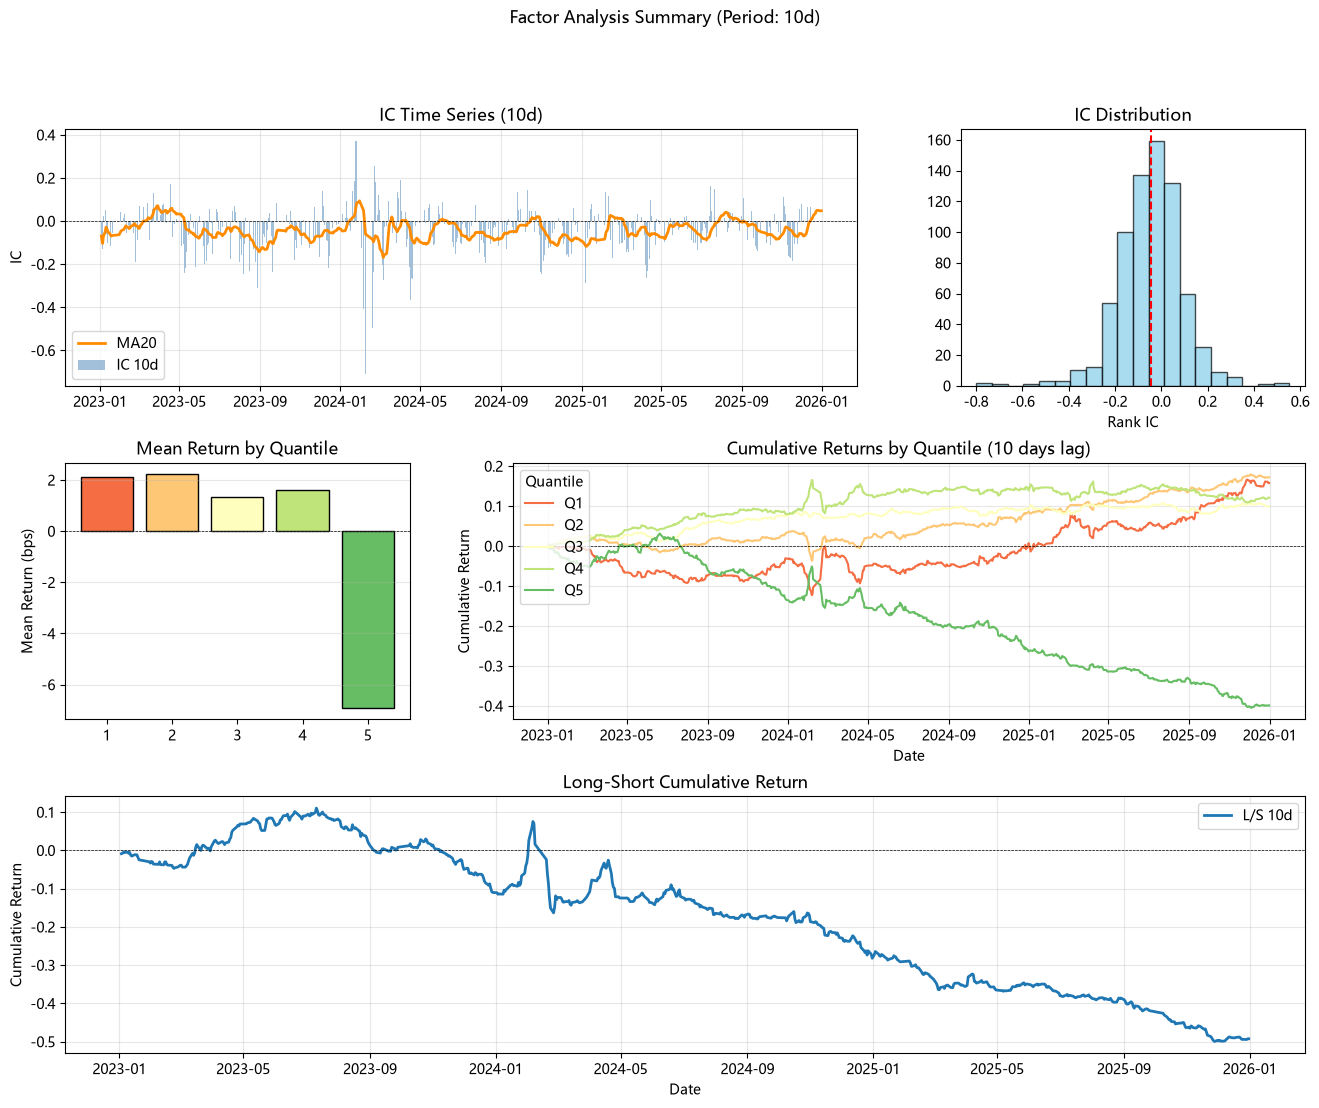

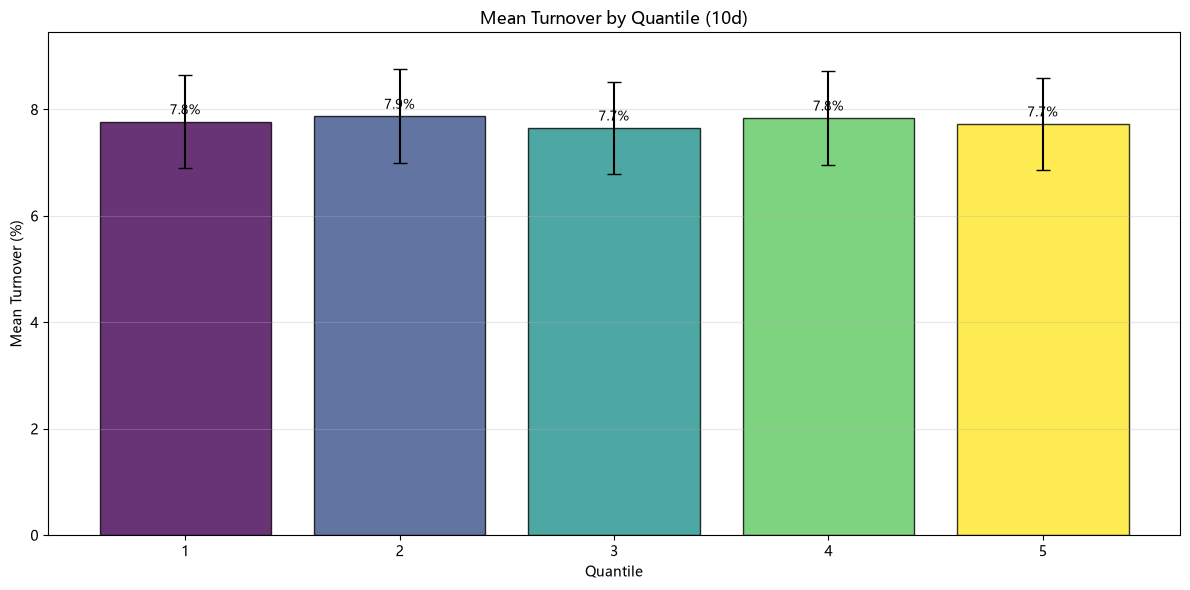

In [9]:
daily_price_volume.backtest(daily_price_volume_lf,'2023-01-01','2025-12-31','DailyPriceVolume_exret_000001_5d',5,10)